In [3]:
import pandas as pd

# load dataset
data = pd.read_csv('IndoLeX_Database.csv')

#Menampilkan 5 data teratas
print(data.head(5))

print(data.tail(10))

print(data.columns)

print(data.info())




       word  frequency      category root  \
0       aba       1062   kbbi_direct  aba   
1    peraba        142   kbbi_direct  aba   
2  perabaan         59   kbbi_direct  aba   
3    teraba         44   kbbi_direct  aba   
4    beraba        132  kbbi_derived  aba   

                                          Definition  
0                                                NaN  
1  peraba\tpe.ra.ba<br>[n] (1) yg meraba; (2) ala...  
2  perabaan\tpe.ra.ba.an<br>[n] proses, cara, per...  
3  teraba\tte.ra.ba<br>[v] meraba secara tidak se...  
4                                                NaN  
             word  frequency      category       root  \
131524   zulhijah        423   kbbi_direct   zulhijah   
131525  zulkaidah        266   kbbi_direct  zulkaidah   
131526       zulu        644   kbbi_direct       zulu   
131527     zuriah         12   kbbi_direct     zuriah   
131528     zuriat         67   kbbi_direct     zuriat   
131529        zus         67   kbbi_direct        zus   


In [4]:
#Melihat ukuran dataset
print(data.shape)
#melihat jumlah dokumen dalam dataset
jumlah_dokumen = len(data)
print("Jumlah dokumen:", jumlah_dokumen)
#  Memilih Kolom Teks
text_column = "Definition"
texts = data[text_column]
print("kolom Definition:",texts.head(9))

#melihat contoh teks dari kolom Definition
for text in texts.head(10):
    print(text)
    print("-" * 80)

(131534, 5)
Jumlah dokumen: 131534
kolom Definition: 0                                                  NaN
1    peraba\tpe.ra.ba<br>[n] (1) yg meraba; (2) ala...
2    perabaan\tpe.ra.ba.an<br>[n] proses, cara, per...
3    teraba\tte.ra.ba<br>[v] meraba secara tidak se...
4                                                  NaN
5                                                  NaN
6                                                  NaN
7                                                  NaN
8                                                  NaN
Name: Definition, dtype: str
nan
--------------------------------------------------------------------------------
peraba	pe.ra.ba<br>[n] (1) yg meraba; (2) alat untuk meraba<br><br>[a] pemarah
--------------------------------------------------------------------------------
perabaan	pe.ra.ba.an<br>[n] proses, cara, perbuatan meraba
--------------------------------------------------------------------------------
teraba	te.ra.ba<br>[v] meraba secara t

In [5]:
#
data.isnull().sum()
print(data.isnull().sum())
#
data[text_column].isnull().sum()
print("Jumlah dokumen sebelum menghapus data kosong:", len(data))
#
data_clean = data.dropna(subset=[text_column])
print("Jumlah dokumen setelah menghapus data kosong:", len(data_clean))



word              0
frequency         0
category          0
root              0
Definition    93304
dtype: int64
Jumlah dokumen sebelum menghapus data kosong: 131534
Jumlah dokumen setelah menghapus data kosong: 38230


In [6]:
#
data.duplicated().sum()
print("Jumlah dokumen yang merupakan duplikat:", data.duplicated().sum())
#
data = data.drop_duplicates(subset=[text_column])
print("Jumlah dokumen setelah menghapus duplikat:", len(data))
#
data["jumlah_karakter"] = data[text_column].fillna("").astype(str).apply(len)
print(data["jumlah_karakter"].head(10))
#
data["jumlah_kata"] = data[text_column].fillna("").astype(str).apply(
    lambda x: len(x.split())
)
print(data["jumlah_kata"].head(10))
#

data["jumlah_kata"].describe()
print(data["jumlah_kata"].describe())


Jumlah dokumen yang merupakan duplikat: 0
Jumlah dokumen setelah menghapus duplikat: 38231
0       0
1      78
2      58
3      50
24    100
34     75
35    122
36    243
37     71
38     94
Name: jumlah_karakter, dtype: int64
0      0
1     10
2      6
3      6
24    14
34    12
35    17
36    30
37     6
38    12
Name: jumlah_kata, dtype: int64
count    38231.000000
mean        15.327169
std         12.374099
min          0.000000
25%          7.000000
50%         12.000000
75%         20.000000
max        205.000000
Name: jumlah_kata, dtype: float64


In [7]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")
from nltk.tokenize import sent_tokenize
text = "Saya belajar NLP. NLP sangat menarik."
sentences = sent_tokenize(text)
print(sentences)

#
data["jumlah_kalimat"] = data[text_column].fillna("").astype(str).apply(
    lambda x: len(sent_tokenize(x))
)
print(data["jumlah_kalimat"].head(10))

print("Jumlah dokumen :", len(data))
print("Jumlah kata    :", data["jumlah_kata"].sum())
print("Jumlah kalimat :", data["jumlah_kalimat"].sum())
print("Jumlah karakter:", data["jumlah_karakter"].sum())

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


['Saya belajar NLP.', 'NLP sangat menarik.']
0     0
1     1
2     1
3     1
24    1
34    1
35    1
36    1
37    1
38    1
Name: jumlah_kalimat, dtype: int64
Jumlah dokumen : 38231
Jumlah kata    : 585973
Jumlah kalimat : 38965
Jumlah karakter: 4430426


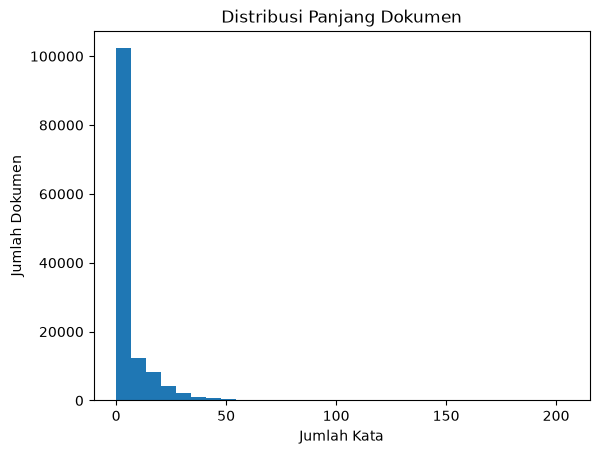

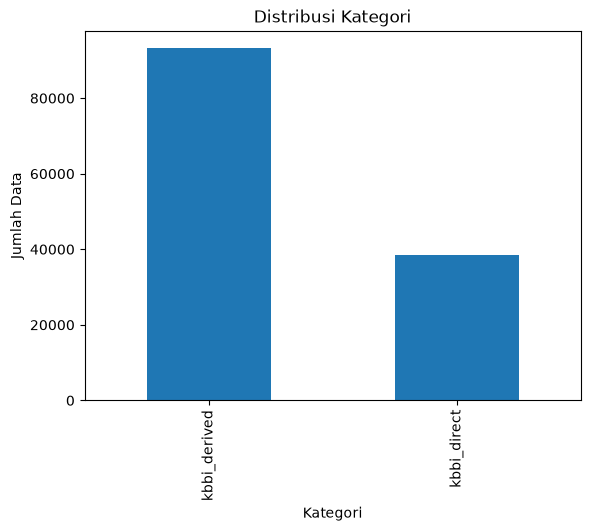

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("IndoLeX_Database.csv")
data["jumlah_kata"] = data["Definition"].fillna("").astype(str).apply(lambda teks: len(teks.split()))
plt.hist(data["jumlah_kata"], bins=30)
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.show()

if "category" in data.columns:
    data["category"].value_counts().plot(kind="bar")
    plt.xlabel("Kategori")
    plt.ylabel("Jumlah Data")
    plt.title("Distribusi Kategori")
    plt.show()